# Final 03 — Classificação

**Alvo**: o cluster do KMeans (`final/02_clusterizacao`). **X**: as 15 features candidatas (sem
`Species`).

1. **Treino**: `GridSearchCV` com `StratifiedKFold(5)` e `balanced_accuracy` (classe `Classifier`).
   O CV faz o papel de validação na escolha dos hiperparâmetros.
2. **Validação**: o melhor pipeline de cada modelo prevê a validação (`df_test=df_valid` na classe,
   com `nome_teste="validação"`).
3. **Teste**: o mesmo pipeline prevê o teste, uma vez só.

**Atenção na leitura**: o cluster é uma função das features do clustering, que também estão em X.
O classificador reaprende a fronteira do KMeans, então acurácia ≈ 100% é esperada. Não é vazamento
entre treino e teste; é circularidade entre alvo e features.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, precision_score, recall_score)

warnings.filterwarnings("ignore")


def encontrar_raiz_repo(marcadores=(".git", "data")):
    for pasta in [Path.cwd(), *Path.cwd().parents]:
        if all((pasta / m).exists() for m in marcadores):
            return pasta
    raise FileNotFoundError(f"Nao achei {marcadores} subindo a partir de {Path.cwd()}")


RAIZ = encontrar_raiz_repo()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from notebooks.src.classifier import Classifier
from notebooks.src.graficos import CONJUNTOS, grafico_metricas

pd.set_option("display.width", 200)

## 1. Dados

In [2]:
clusters = pd.read_csv(RAIZ / "data/processed/final/clusters_risco.csv", index_col=0)
pasta = RAIZ / "data/processed/df_estruturada"
dados = {
    nome: pd.read_csv(pasta / f"df_{arq}_risco.csv", index_col=0).join(clusters[["cluster"]])
    for nome, arq in zip(CONJUNTOS, ["train", "valid", "test"])
}
df_train, df_valid, df_test = dados["treino"], dados["validação"], dados["teste"]

print({nome: df.shape for nome, df in dados.items()})
clusters.groupby("cluster")["perfil"].first()

{'treino': (1558, 17), 'validação': (445, 17), 'teste': (223, 17)}


cluster
0    C0: carbapenemase serina (plasm. 70%, 4.1 clas...
1      C1: MBL + ESBL + PMQR (plasm. 69%, 5.6 classes)
2    C2: sem mecanismo principal adquirido (plasm. ...
3    C3: carbapenemase serina + ESBL (plasm. 61%, 4...
4    C4: carbapenemase serina + metilase 16S (plasm...
5            C5: ESBL + PMQR (plasm. 62%, 5.8 classes)
6                   C6: ESBL (plasm. 68%, 5.0 classes)
7    C7: sem mecanismo principal adquirido (plasm. ...
Name: perfil, dtype: object

## 2. Treino (GridSearchCV) e validação

Pipeline de cada modelo: `StandardScaler` (dentro do pipeline, refeito a cada fold) →
`VarianceThreshold` → `SelectKBest(f_classif)` → modelo.

--- Treinando knn (1558 amostras, 15 features) ---



--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor balanced_accuracy (CV): 0.9903


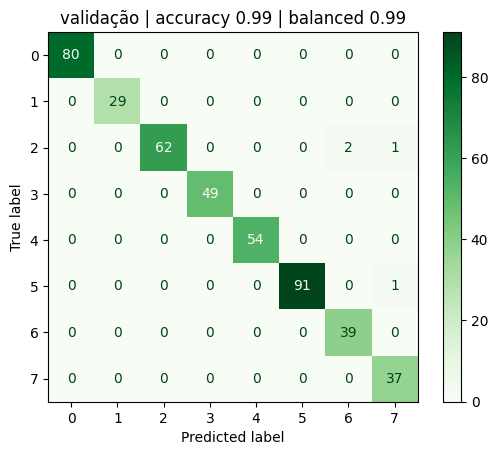


Classification Report (validação):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        80
           1       1.00      1.00      1.00        29
           2       1.00      0.95      0.98        65
           3       1.00      1.00      1.00        49
           4       1.00      1.00      1.00        54
           5       1.00      0.99      0.99        92
           6       0.95      1.00      0.97        39
           7       0.95      1.00      0.97        37

    accuracy                           0.99       445
   macro avg       0.99      0.99      0.99       445
weighted avg       0.99      0.99      0.99       445

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__has_carbapenemase
2. num__has_mbl
3. num__has_carbapenemase_serina
4. num__n_carbapenemases
5. num__has_esbl
6. num_


--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'linear', 'var_threshold__threshold': 0.0001}
Melhor balanced_accuracy (CV): 0.9949


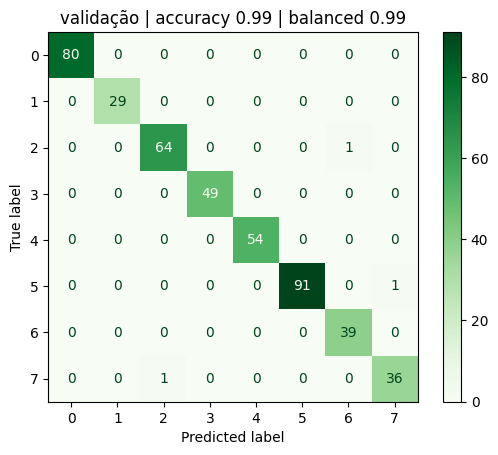


Classification Report (validação):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        80
           1       1.00      1.00      1.00        29
           2       0.98      0.98      0.98        65
           3       1.00      1.00      1.00        49
           4       1.00      1.00      1.00        54
           5       1.00      0.99      0.99        92
           6       0.97      1.00      0.99        39
           7       0.97      0.97      0.97        37

    accuracy                           0.99       445
   macro avg       0.99      0.99      0.99       445
weighted avg       0.99      0.99      0.99       445

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__has_carbapenemase
2. num__has_mbl
3. num__has_carbapenemase_serina
4. num__n_carbapenemases
5. num__has_esbl
6. num_


--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'entropy', 'rf__max_depth': None, 'rf__min_samples_split': 5, 'rf__n_estimators': 100, 'var_threshold__threshold': 0.0001}
Melhor balanced_accuracy (CV): 0.9968


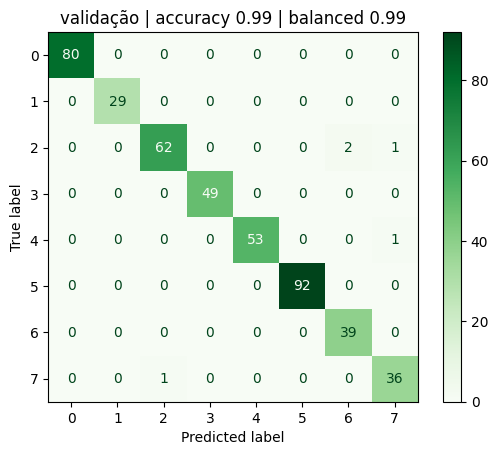


Classification Report (validação):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        80
           1       1.00      1.00      1.00        29
           2       0.98      0.95      0.97        65
           3       1.00      1.00      1.00        49
           4       1.00      0.98      0.99        54
           5       1.00      1.00      1.00        92
           6       0.95      1.00      0.97        39
           7       0.95      0.97      0.96        37

    accuracy                           0.99       445
   macro avg       0.99      0.99      0.99       445
weighted avg       0.99      0.99      0.99       445

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__has_carbapenemase
2. num__has_mbl
3. num__has_carbapenemase_serina
4. num__n_carbapenemases
5. num__has_esbl
6. num_


--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.2, 'gb__max_depth': 3, 'gb__n_estimators': 100, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor balanced_accuracy (CV): 0.9944


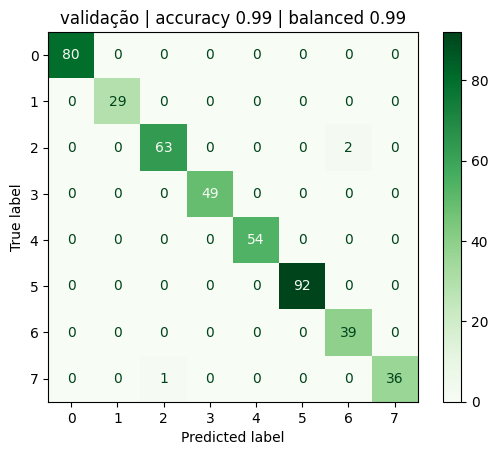


Classification Report (validação):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        80
           1       1.00      1.00      1.00        29
           2       0.98      0.97      0.98        65
           3       1.00      1.00      1.00        49
           4       1.00      1.00      1.00        54
           5       1.00      1.00      1.00        92
           6       0.95      1.00      0.97        39
           7       1.00      0.97      0.99        37

    accuracy                           0.99       445
   macro avg       0.99      0.99      0.99       445
weighted avg       0.99      0.99      0.99       445

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__has_carbapenemase
2. num__has_mbl
3. num__has_carbapenemase_serina
4. num__n_carbapenemases
5. num__has_esbl
6. num_


--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': np.float64(0.1), 'var_threshold__threshold': 0.0001}
Melhor balanced_accuracy (CV): 0.9688


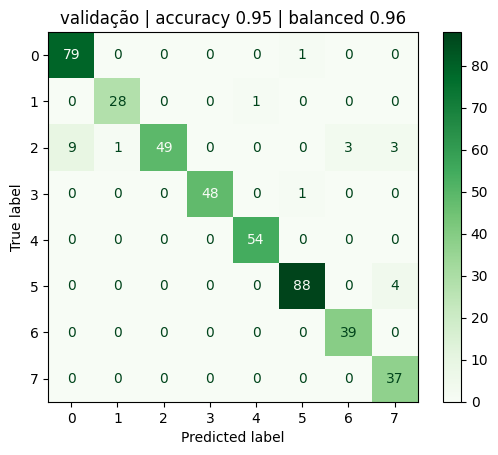


Classification Report (validação):
              precision    recall  f1-score   support

           0       0.90      0.99      0.94        80
           1       0.97      0.97      0.97        29
           2       1.00      0.75      0.86        65
           3       1.00      0.98      0.99        49
           4       0.98      1.00      0.99        54
           5       0.98      0.96      0.97        92
           6       0.93      1.00      0.96        39
           7       0.84      1.00      0.91        37

    accuracy                           0.95       445
   macro avg       0.95      0.96      0.95       445
weighted avg       0.95      0.95      0.95       445

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__has_carbapenemase
2. num__has_mbl
3. num__has_carbapenemase_serina
4. num__n_carbapenemases
5. num__has_esbl
6. num_


--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'tanh', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (10,), 'mlp__solver': 'adam', 'var_threshold__threshold': 0.0001}
Melhor balanced_accuracy (CV): 0.9971


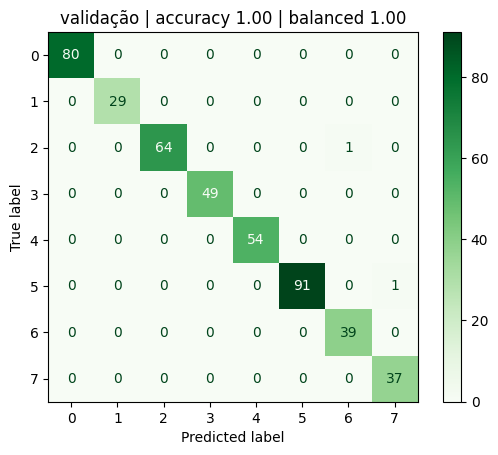


Classification Report (validação):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        80
           1       1.00      1.00      1.00        29
           2       1.00      0.98      0.99        65
           3       1.00      1.00      1.00        49
           4       1.00      1.00      1.00        54
           5       1.00      0.99      0.99        92
           6       0.97      1.00      0.99        39
           7       0.97      1.00      0.99        37

    accuracy                           1.00       445
   macro avg       0.99      1.00      1.00       445
weighted avg       1.00      1.00      1.00       445

Total de variáveis originais pré-processadas: 15
Total de variáveis após VarianceThreshold:    15
Total de variáveis selecionadas no modelo:    15

--- Lista das Variáveis Selecionadas ---
1. num__has_carbapenemase
2. num__has_mbl
3. num__has_carbapenemase_serina
4. num__n_carbapenemases
5. num__has_esbl
6. num_

In [3]:
MODELOS = {"knn": "k-NN", 
           "svm": "SVM", 
           "rf": "Random Forest", 
           "gbm": "Gradient Boosting",
           "nb": "Naive Bayes", 
           "nn": "Rede neural (MLP)"}

clf = Classifier(df_train, target="cluster", df_test=df_valid, descartar=["Species"], nome_teste="validação")
for modelo in MODELOS:
    clf.classify(modelo)

## 3. Métricas no treino, na validação e no teste

- **treino**: o pipeline final prevendo o próprio treino (ajuste); o score de CV fica na coluna
  `balanced_accuracy_cv`.
- **validação** e **teste**: dados que o modelo não viu.

In [4]:
def metricas(y, pred):
    return {
        "acuracia": accuracy_score(y, pred),
        "acuracia_balanceada": balanced_accuracy_score(y, pred),
        "precision_weighted": precision_score(y, pred, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y, pred, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y, pred, average="weighted", zero_division=0),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
    }


predicoes = {m: {c: clf.modelos_[m].predict(df[clf.X.columns]) for c, df in dados.items()} for m in MODELOS}
linhas = [{"modelo": MODELOS[m], "conjunto": c, **metricas(dados[c]["cluster"], predicoes[m][c]),
           "balanced_accuracy_cv": clf.cv_scores_[m] if c == "treino" else np.nan}
          for m in MODELOS for c in CONJUNTOS]
metricas_classif = pd.DataFrame(linhas)
metricas_classif.set_index(["modelo", "conjunto"]).round(4)

acuracia  acuracia_balanceada  precision_weighted  recall_weighted  f1_weighted  f1_macro  balanced_accuracy_cv
modelo            conjunto                                                                                                                  
k-NN              treino       1.0000               1.0000              1.0000           1.0000       1.0000    1.0000                0.9903
                  validação    0.9910               0.9929              0.9915           0.9910       0.9910    0.9899                   NaN
                  teste        0.9865               0.9880              0.9870           0.9865       0.9865    0.9877                   NaN
SVM               treino       0.9987               0.9988              0.9987           0.9987       0.9987    0.9985                0.9949
                  validação    0.9933               0.9933              0.9933           0.9933       0.9933    0.9924                   NaN
                  teste        0.9955               0.9954              0.9957           0.9955       0.9955    0.9951                   NaN
Random Forest     treino       1.0000               1.0000              1.0000           1.0000       1.0000    1.0000                0.9968
                  validação    0.9888               0.9885              0.9890           0.9888       0.9888    0.9868                   NaN
                  teste        0.9955               0.9954              0.9957           0.9955       0.9955    0.9957                   NaN
Gradient Boosting treino       1.0000               1.0000              1.0000           1.0000       1.0000    1.0000                0.9944
                  validação    0.9933               0.9928              0.9934           0.9933       0.9933    0.9923                   NaN
                  teste        0.9910               0.9907              0.9914           0.9910       0.9909    0.9907                   NaN
Naive Bayes       treino       0.9679               0.9711              0.9701           0.9679       0.9674    0.9691                0.9688
                  validação    0.9483               0.9554              0.9531           0.9483       0.9471    0.9487                   NaN
                  teste        0.9865               0.9857              0.9873           0.9865       0.9865    0.9866                   NaN
Rede neural (MLP) treino       0.9994               0.9995              0.9994           0.9994       0.9994    0.9995                0.9971
                  validação    0.9955               0.9967              0.9956           0.9955       0.9955    0.9951                   NaN
                  teste        0.9955               0.9961              0.9957           0.9955       0.9955    0.9957                   NaN

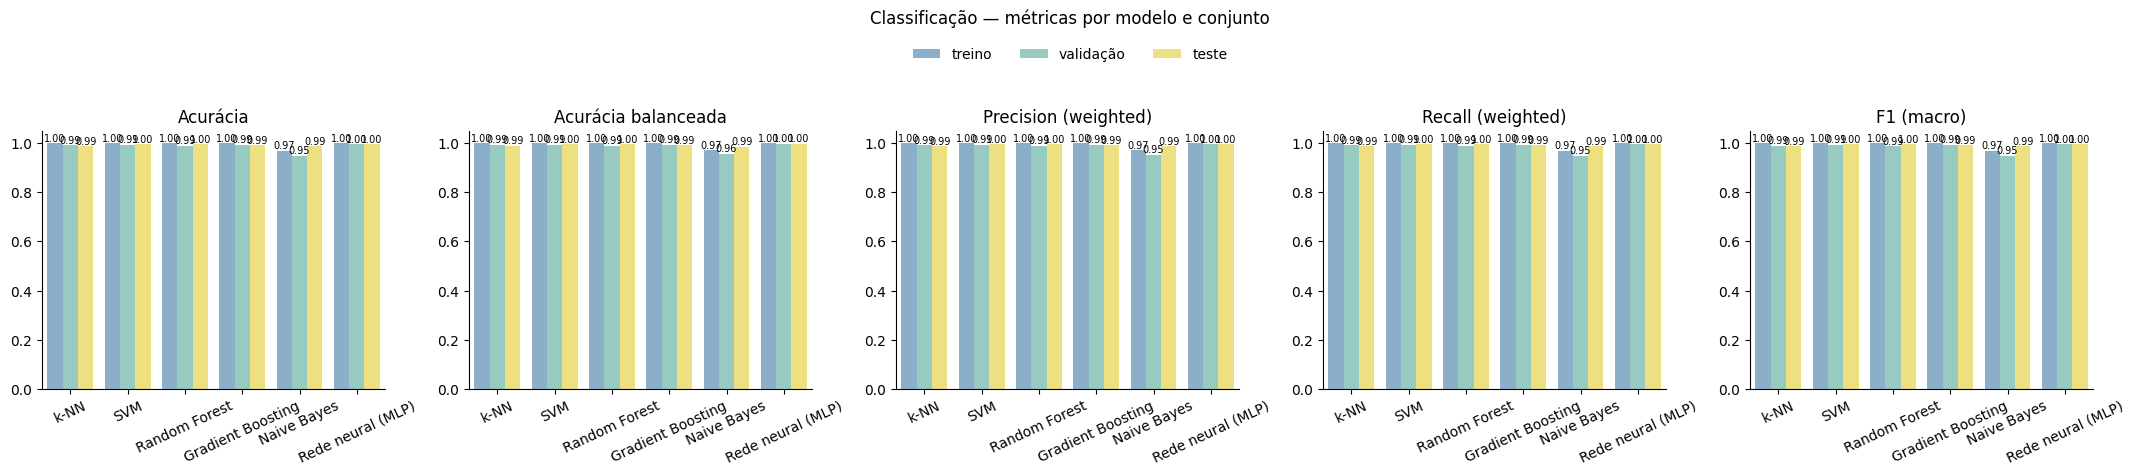

In [5]:
METRICAS_CLASSIF = {
    "acuracia": "Acurácia",
    "acuracia_balanceada": "Acurácia balanceada",
    "precision_weighted": "Precision (weighted)",
    "recall_weighted": "Recall (weighted)",
    "f1_macro": "F1 (macro)",
}
grafico_metricas(metricas_classif, METRICAS_CLASSIF, "Classificação — métricas por modelo e conjunto",
                 formatos={c: "%.2f" for c in METRICAS_CLASSIF})
plt.show()

## 4. Estabilidade: qui² de homogeneidade (treino × teste)

As classes **preditas** no teste estão distribuídas do mesmo jeito que no treino (a referência,
como no qui² do `final/02_clusterizacao`)?
H0: a distribuição das classes preditas é igual nos dois conjuntos (gl = (nº de classes − 1) × 1).

Com acurácia ≈ 100%, as classes preditas ≈ classes reais, então o teste mede sobretudo se a divisão
treino/teste preservou as proporções dos clusters.

In [6]:
linhas = []
for m, nome in MODELOS.items():
    tabela = pd.crosstab(
        np.repeat(["treino", "teste"], [len(df_train), len(df_test)]),
        np.concatenate([predicoes[m]["treino"], predicoes[m]["teste"]]),
    )
    chi2, p, gl, _ = chi2_contingency(tabela)
    linhas.append({"modelo": nome, "qui2": chi2, "gl": gl, "p_valor": p,
                   "conclusao": "homogênea (não rejeita H0)" if p > 0.05 else "diferente (rejeita H0)"})
pd.DataFrame(linhas).round(4)

,modelo,qui2,gl,p_valor,conclusao
0,k-NN,6.1930,7,0.5174,homogênea (não rejeita H0)
1,SVM,3.7690,7,0.8060,homogênea (não rejeita H0)
2,Random Forest,4.3464,7,0.7391,homogênea (não rejeita H0)
3,Gradient Boosting,3.4713,7,0.8383,homogênea (não rejeita H0)
4,Naive Bayes,3.5697,7,0.8278,homogênea (não rejeita H0)
5,Rede neural (MLP),5.5845,7,0.5890,homogênea (não rejeita H0)


## 5. Matriz de confusão no teste (Random Forest)

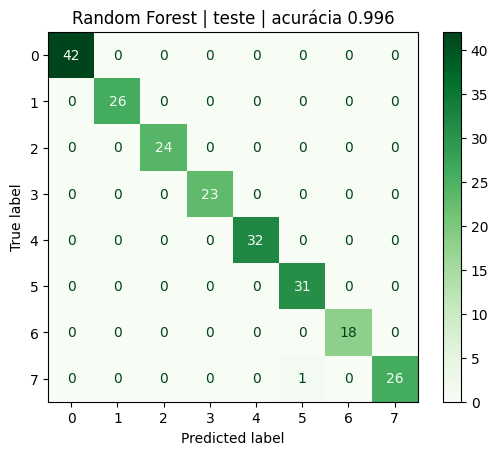

In [7]:
rotulos = sorted(df_test["cluster"].unique())
cm = confusion_matrix(df_test["cluster"], predicoes["rf"]["teste"], labels=rotulos)
ConfusionMatrixDisplay(cm, display_labels=rotulos).plot(cmap=plt.cm.Greens)
plt.title(f"Random Forest | teste | acurácia {accuracy_score(df_test['cluster'], predicoes['rf']['teste']):.3f}")
plt.show()

## Exportação para o app

Um arquivo por modelo em `app/data/df_resultados/classif_<modelo>` (`Dataset` + `Classe_Predita`,
treino e teste, para o qui²), `app/data/test_resultados_classif` (classe real + uma coluna por modelo) e
`metricas_classif.csv` (gráfico de métricas).

In [8]:
from joblib import dump

pasta_app = RAIZ / "app/data"
test_classif = df_test[["cluster"]].copy()
for m in MODELOS:
    df_pred = pd.DataFrame({
        "Dataset": ["Treino"] * len(df_train) + ["Teste"] * len(df_test),
        "Classe_Predita": np.concatenate([predicoes[m]["treino"], predicoes[m]["teste"]]),
    })
    dump(df_pred, pasta_app / "df_resultados" / f"classif_{m}")
    test_classif[m] = predicoes[m]["teste"]
dump(test_classif, pasta_app / "test_resultados_classif")
metricas_classif.round(4).to_csv(pasta_app / "df_resultados/metricas_classif.csv", index=False)
test_classif.head()

,cluster,knn,svm,rf,gbm,nb,nn
sample,,,,,,,
GCA_022210145.1,3,3,3,3,3,3,3
GCA_003183885.1,7,7,7,7,7,7,7
GCA_014771915.1,7,7,7,7,7,7,7
GCA_054478215.1,7,7,7,5,5,7,7
GCA_015537635.1,0,0,0,0,0,0,0
